# MNIST 脉冲编码：Rate、Latency 与 Phase

Section 2 · Part 2 · Task 1：用同一张图片比较三种编码。这里只生成输入脉冲，不训练分类网络。

先在项目根目录运行 `uv sync --locked --extra cpu` 和 `uv run --locked --extra cpu python mnist/prepare_data.py`，然后依次执行本 Notebook。图像是未标准化的 [0, 1] 像素强度；黑色背景不发放。


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from torchvision.datasets import MNIST
from torchvision.transforms import ToTensor

root = Path.cwd().parent if Path.cwd().name == "mnist" else Path.cwd()
sys.path.insert(0, str(root / "mnist"))

In [2]:
from encoding import latency_encode, phase_encode, rate_encode

## 1. 三种编码规则

设像素强度 $x\in[0,1]$、时间步数 $T$，每个像素对应一个输入神经元。输出为二值脉冲 $S_{k,i}\in\{0,1\}$。

- **Rate**：每个时间步独立以概率 $x_i$ 发放；亮度由发放数量的统计规律表示，单次结果受随机性影响。
- **Latency**：非零像素只发放一次，时刻为 $k_i=\operatorname{round}((1-x_i)(T-1))$；越亮越早。
- **Phase（自选）**：周期为 $P$，非零像素每周期在 $\phi_i=\operatorname{round}((1-x_i)(P-1))$ 发放；亮度由周期内相位表示。它会重复发放，与单次 Latency 不同。

黑色像素约定为不发放。时间和相位取整会损失精度；这里的时间步未指定实际时长，因此下面报告每神经元每步平均脉冲数，不将它称为 Hz。

参考：[Diehl & Cook（2015）：MNIST 强度与输入发放率](https://www.frontiersin.org/journals/computational-neuroscience/articles/10.3389/fncom.2015.00099/full)；[Comsa 等（2021）：时序与首次发放编码](https://www.frontiersin.org/journals/neuroscience/articles/10.3389/fnins.2021.712667/full)；[Chen 等（2021）：神经振荡与脉冲相位](https://cdn.aaai.org/ojs/16870/16870-13-20364-1-2-20210518.pdf)。本例采用简化的离散相位规则，并非复现这些论文的完整模型。


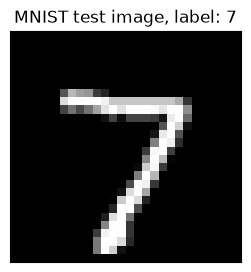

In [3]:
dataset = MNIST(
    root / "mnist" / "data", train=False, download=False, transform=ToTensor()
)
image_tensor, label = dataset[0]
image = image_tensor.squeeze(0).numpy()
steps, period, seed = 100, 20, 42
trains = {
    "Rate": rate_encode(image, steps, np.random.default_rng(seed)),
    "Latency": latency_encode(image, steps),
    "Phase": phase_encode(image, steps, period),
}
fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(image, cmap="gray", vmin=0, vmax=1)
ax.set(title=f"MNIST test image, label: {label}", xticks=[], yticks=[])
plt.show()

## 2. 输入脉冲 Raster

横轴是时间步；纵轴是按行展开的 784 个像素对应的输入神经元。每个点表示一次输入脉冲；三幅图使用相同图片和坐标范围。


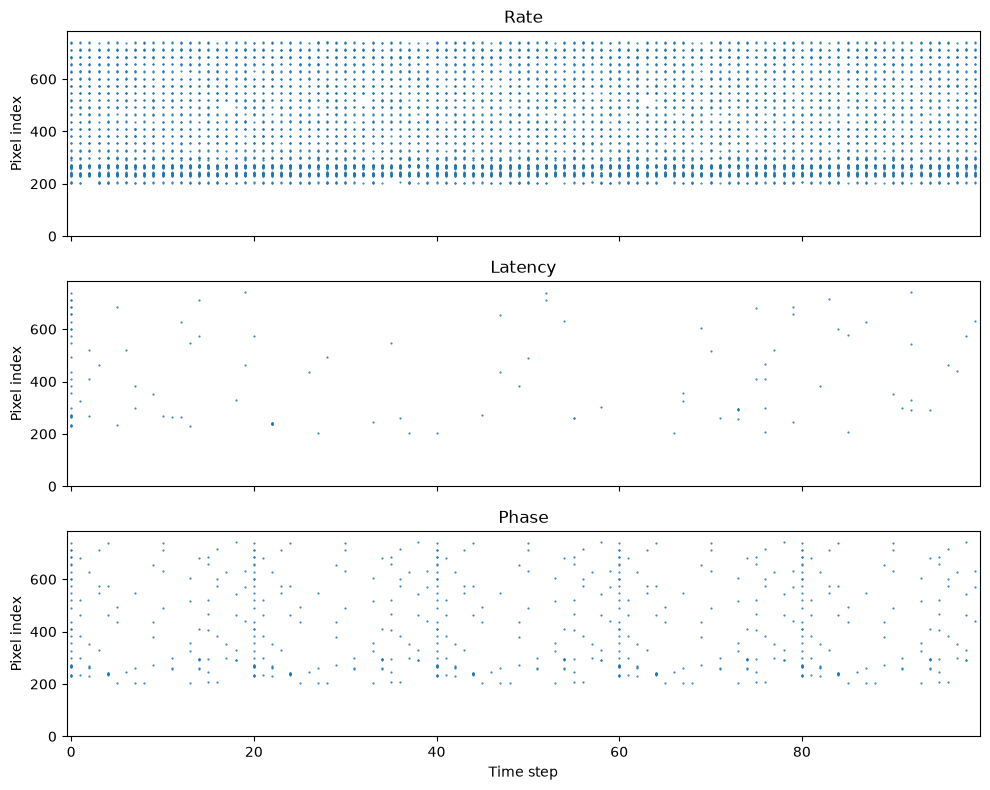

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, (name, spikes) in zip(axes, trains.items(), strict=True):
    time, neuron = np.nonzero(spikes.reshape(steps, -1))
    ax.scatter(time, neuron, s=1, marker=".")
    ax.set(
        title=name,
        ylabel="Pixel index",
        xlim=(-0.5, steps - 0.5),
        ylim=(-0.5, image.size - 0.5),
    )
axes[-1].set_xlabel("Time step")
fig.tight_layout()
plt.show()

## 3. 脉冲数量与时间分布

平均发放率按 `脉冲总数 / (神经元数 × 时间步数)` 计算；这里统计所有像素，包括不发放的背景。曲线展示每一步发放的输入神经元数。Rate 结果固定随机种子，可重复但仍只代表一次采样。


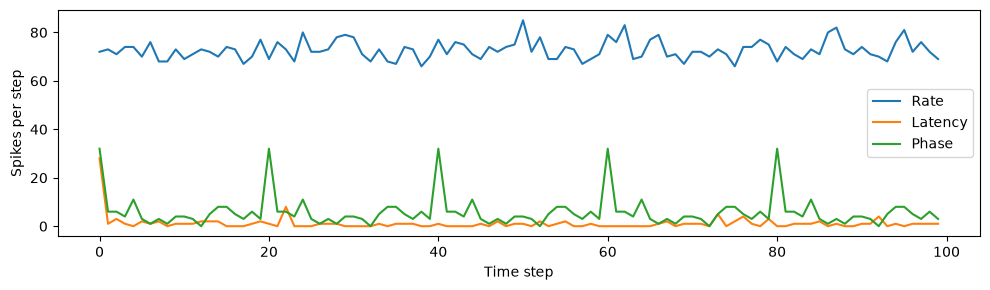

Encoding     Spikes  Per neuron/step  Active pixels
Rate           7270           0.0927            116
Latency         116           0.0015            116
Phase           580           0.0074            116


In [5]:
print(f"{'Encoding':<10} {'Spikes':>8} {'Per neuron/step':>16} {'Active pixels':>14}")
for name, spikes in trains.items():
    count = int(spikes.sum())
    active = int(spikes.any(axis=0).sum())
    print(f"{name:<10} {count:>8} {count / spikes.size:>16.4f} {active:>14}")
fig, ax = plt.subplots(figsize=(10, 3))
for name, spikes in trains.items():
    ax.plot(np.arange(steps), spikes.sum(axis=(1, 2)), label=name)
ax.set(xlabel="Time step", ylabel="Spikes per step")
ax.legend()
fig.tight_layout()
plt.show()

## 4. 如何理解结果

- Rate 用一段时间内的发放数量表示亮度；单次发放时间是随机的，需要较长时间或多次采样才能减小波动。
- Latency 用第一次发放的绝对时间表示亮度；Phase 用每个周期内的相对时刻表示亮度。两者都依赖时间顺序，但 Phase 在多个周期重复，使脉冲总数与周期数有关。
- 静态图像本身没有真实时间信息；把它展开为脉冲可以提供时间维度上的表示，也会带来编码和多时间步计算开销。本例的脉冲数只反映输入活动，不能直接当作能耗或分类性能。

下一任务需把三种编码接入相同 SNN，控制训练条件并比较准确率、隐藏层活动和推理时间；本 Notebook 的结果尚不能回答哪种分类效果更好。

在上述默认设置下，这张数字 7 的 Latency 编码产生 116 个脉冲；Phase 使用 5 个完整周期，每个非背景像素发放 5 次，共 580 个。Rate 的 7270 个脉冲是固定随机种子下的一次结果；换种子会改变数量。
